In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

In [3]:
# importer les données
df = pd.read_csv('/content/sample_data/Car_dataset.csv')
df.head()

,Kms_Driven,Present_Price,Fuel_Type,Seller_Type,Transmission,Age,Selling_Price
0,27000,5.59,Petrol,Dealer,Manual,6,3.35
1,43000,9.54,Diesel,Dealer,Manual,7,4.75
2,6900,9.85,Petrol,Dealer,Manual,3,7.25
3,5200,4.15,Petrol,Dealer,Manual,9,2.85
4,42450,6.87,Diesel,Dealer,Manual,6,4.60


In [4]:
# dimension des données
df.shape

(5861, 7)

In [5]:
# infos des données
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5861 entries, 0 to 5860
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Kms_Driven     5861 non-null   int64  
 1   Present_Price  5861 non-null   float64
 2   Fuel_Type      5861 non-null   object 
 3   Seller_Type    5861 non-null   object 
 4   Transmission   5861 non-null   object 
 5   Age            5861 non-null   int64  
 6   Selling_Price  5861 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 320.7+ KB


### <font color = 'bisque'>Exploration et préparation des données

In [6]:
# selection des variables quantitatives
quantd = df.select_dtypes(include = 'number')
quantd.head()

,Kms_Driven,Present_Price,Age,Selling_Price
0,27000,5.59,6,3.35
1,43000,9.54,7,4.75
2,6900,9.85,3,7.25
3,5200,4.15,9,2.85
4,42450,6.87,6,4.60


In [7]:
# décrire les variables quantitatives
quantd.describe().T

,count,mean,std,min,25%,50%,75%,max
Kms_Driven,5861.0,75209.206108,39198.500980,500.00,53822.000000,71822.000000,87820.000000,538824.000000
Present_Price,5861.0,16.869948,9.659501,0.32,10.552438,15.375776,19.229938,102.661886
Age,5861.0,8.562532,3.099993,2.00,6.000000,8.000000,10.000000,22.000000
Selling_Price,5861.0,10.196217,5.874282,0.10,6.401756,9.049277,11.873727,41.903189


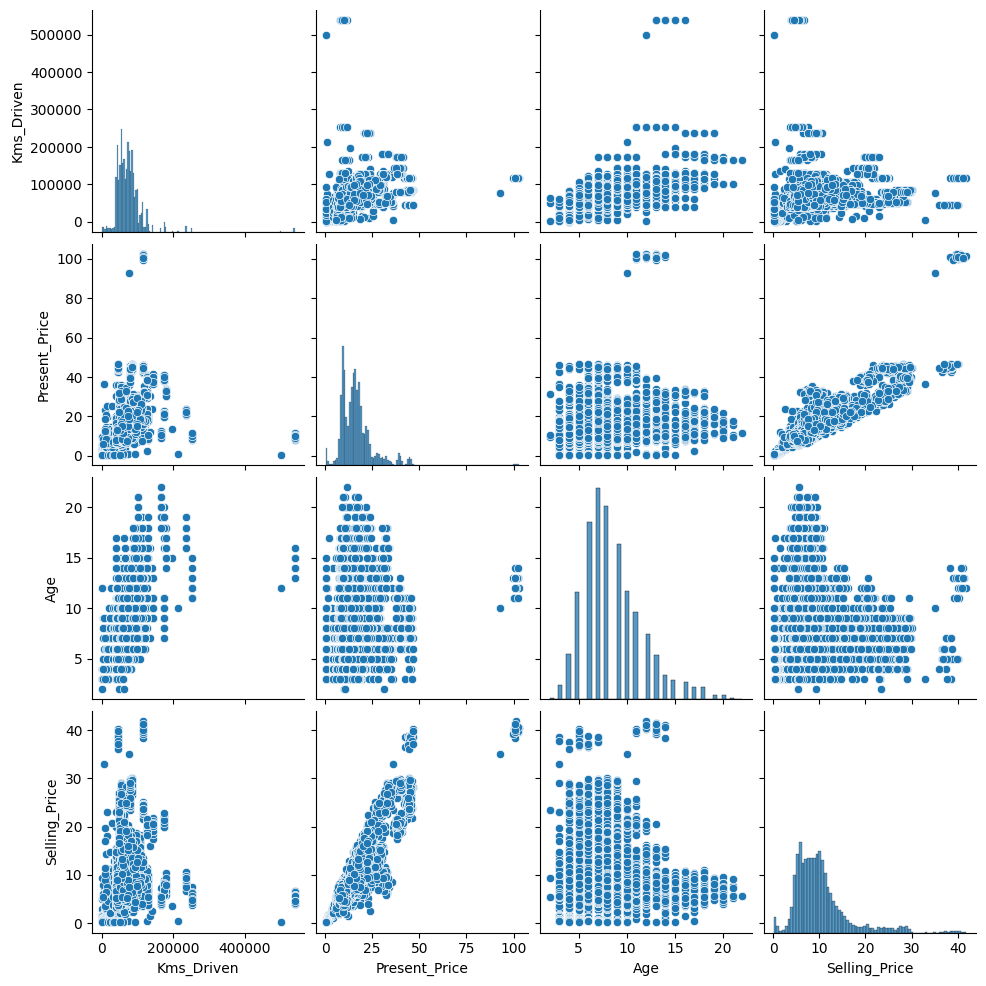

In [8]:
# pairplot des variables quantitatives
sns.pairplot(quantd)
plt.show()

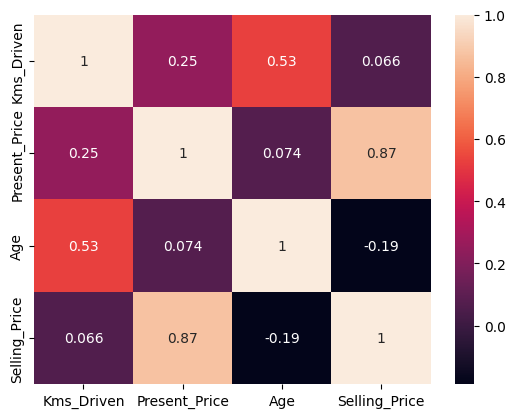

In [9]:
#matrice de correlation
sns.heatmap(quantd.corr(), annot = True)
plt.show()

In [10]:
# fonction de visualisation des boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

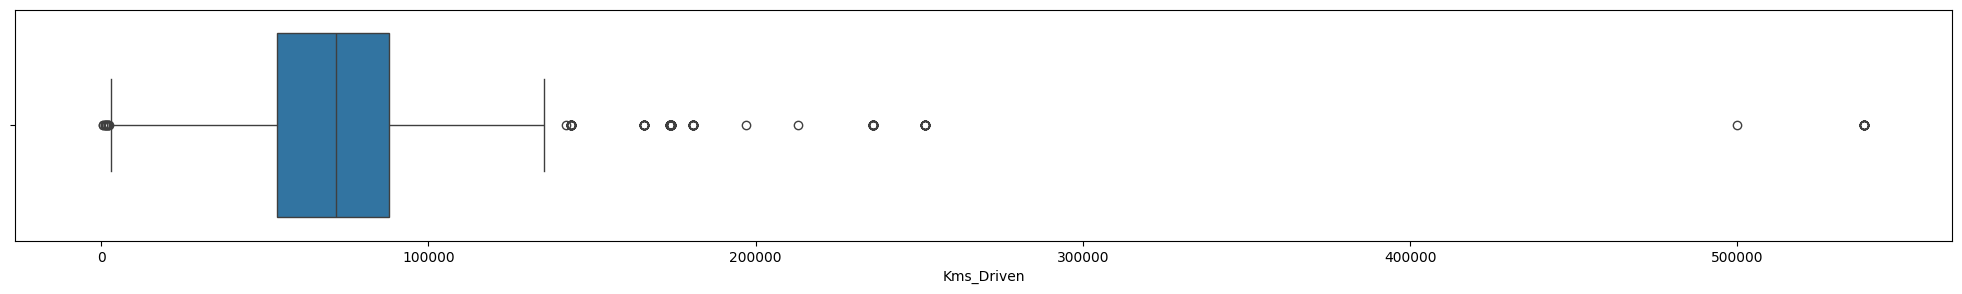

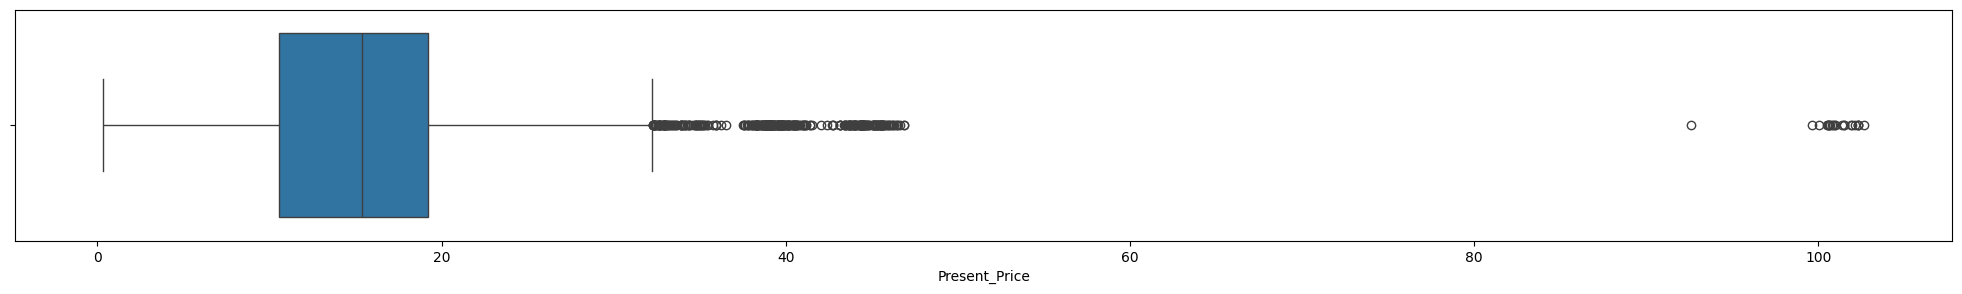

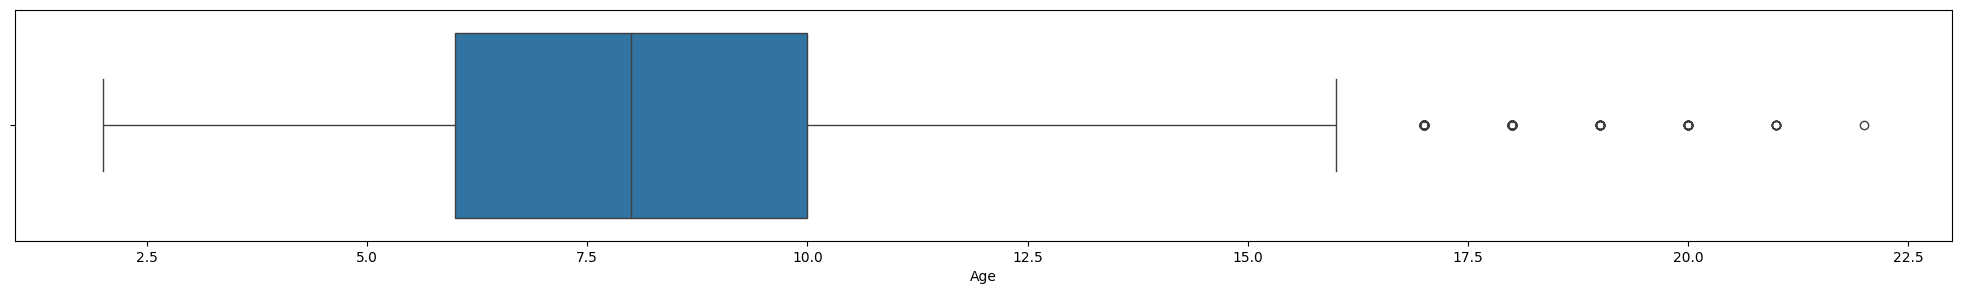

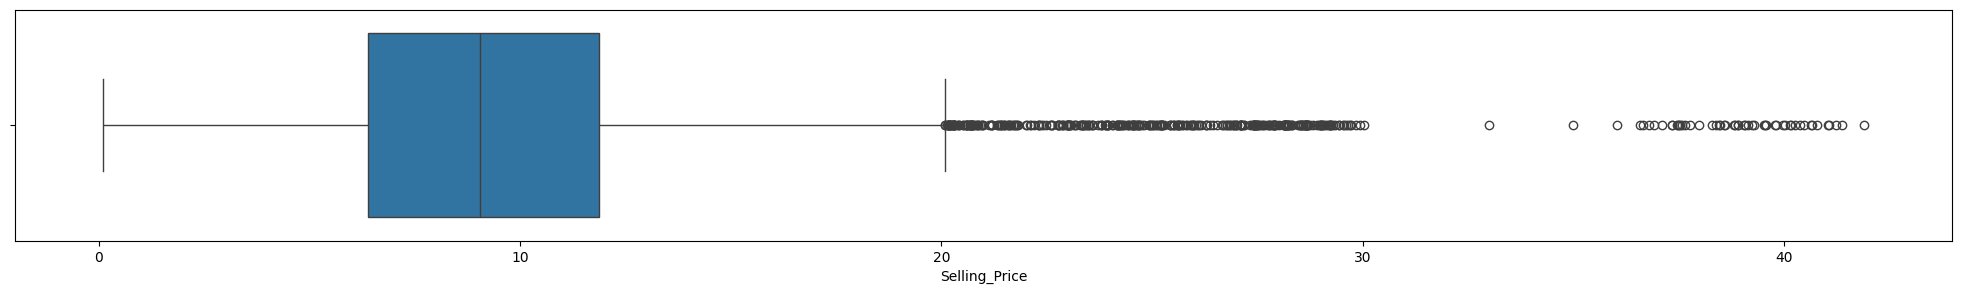

In [11]:
# boxplots des variables quantitatives
for col in quantd.columns:
  boxplot_func(col)

In [12]:
# selection les variables catégorielles
catd = df.select_dtypes(exclude = 'number')
catd.head()

,Fuel_Type,Seller_Type,Transmission
0,Petrol,Dealer,Manual
1,Diesel,Dealer,Manual
2,Petrol,Dealer,Manual
3,Petrol,Dealer,Manual
4,Diesel,Dealer,Manual


In [13]:
# décrire les variables catégorielles
catd.describe().T

,count,unique,top,freq
Fuel_Type,5861,3,Petrol,2743
Seller_Type,5861,2,Dealer,3765
Transmission,5861,2,Automatic,3007


In [14]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
  val = df[col].value_counts()
  fig = px.bar(x=val.index, y=val.values, color = val.index.astype(str), text_auto=True)
  fig.show()

In [15]:
# Diagrammes en barre des variables catégorielles
for col in catd.columns:
  countplot_func(col)

In [16]:
# Imputer les valeurs manquantes des variables catégorielle en utilisant le mode
for col in catd.columns:
  df.fillna({col: df[col].mode()[0]}, inplace = True)

In [18]:
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib
uniques = []
for col in catd.columns:
  uniques.append(np.unique(df[col]).tolist())
import os
# Créer le dossier s'il n'existe pas
os.makedirs('/content/model', exist_ok=True)
# sauvegarde
import joblib as jb
jb.dump(uniques, '/content/model/uniques.joblib')

['/content/model/uniques.joblib']

In [19]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# Créer différents encodeurs pour les variables catégorielles
encoders = []
for i in range(len(catd.columns)):
  encoder = LabelEncoder()
  encoder.fit(df[catd.columns[i]]) # le modèle prend le temps de reconnaitre les classes
  df[catd.columns[i]] = encoder.transform(df[catd.columns[i]]) # encoder les valeurs
  # rajouter l'encoder sur la liste encoders
  encoders.append(encoder)

In [20]:
#afficher
df.head()

,Kms_Driven,Present_Price,Fuel_Type,Seller_Type,Transmission,Age,Selling_Price
0,27000,5.59,2,0,1,6,3.35
1,43000,9.54,1,0,1,7,4.75
2,6900,9.85,2,0,1,3,7.25
3,5200,4.15,2,0,1,9,2.85
4,42450,6.87,1,0,1,6,4.60


In [21]:
import joblib as jb
import os

# Créer le dossier s'il n'existe pas
os.makedirs('/content/model', exist_ok=True)

# sauvegarde les encodeurs
jb.dump(encoders, '/content/model/encoders.joblib')

['/content/model/encoders.joblib']

In [22]:
from sklearn.impute import KNNImputer
# Imputer les valeurs manquantes des variables quantitatives
imputer = KNNImputer(n_neighbors=5)
df[:] = imputer.fit_transform(df)

In [23]:
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan # NaN
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [24]:
#Application du traitement
for col in quantd.columns:
  impute_func(df, col)

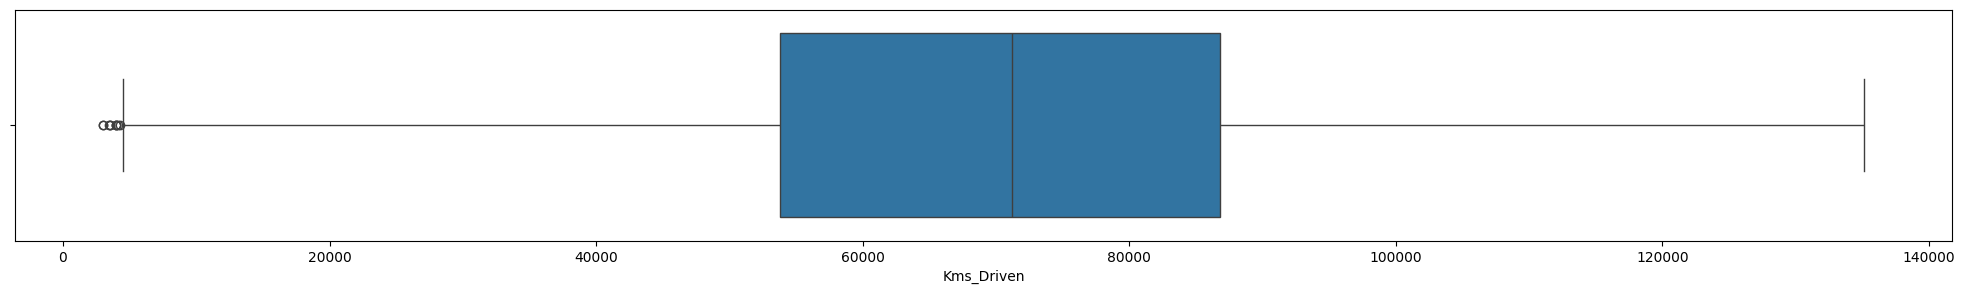

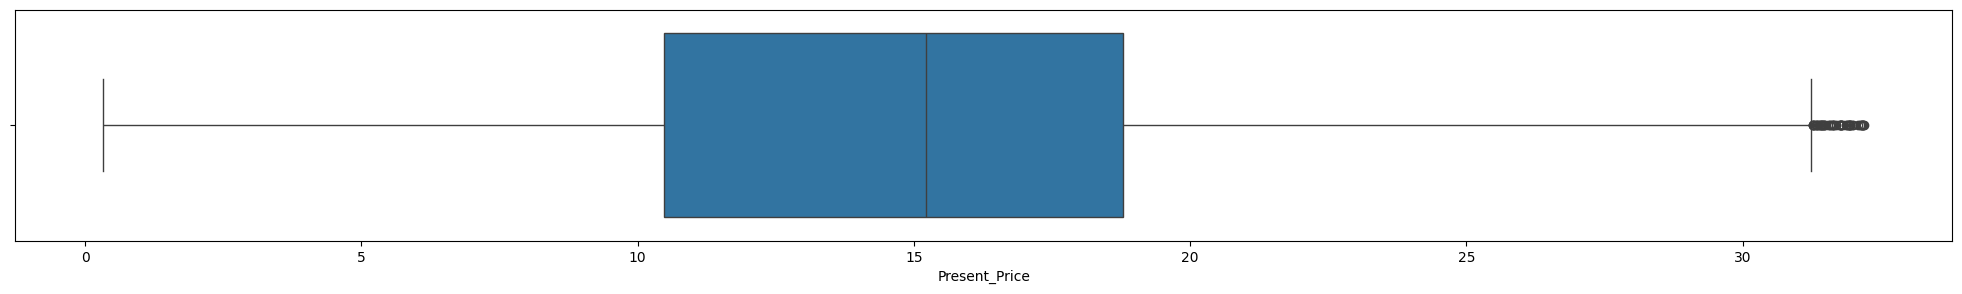

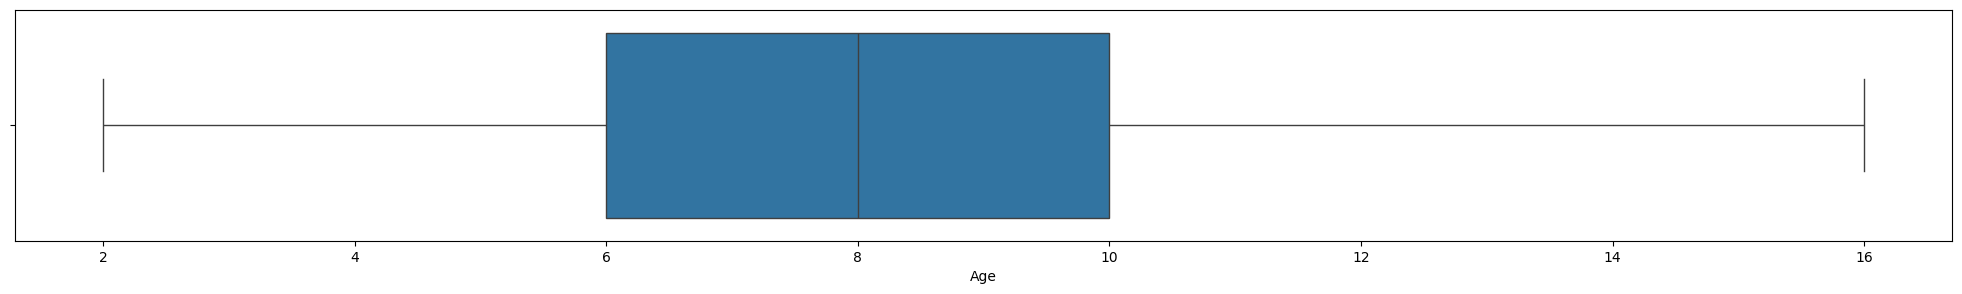

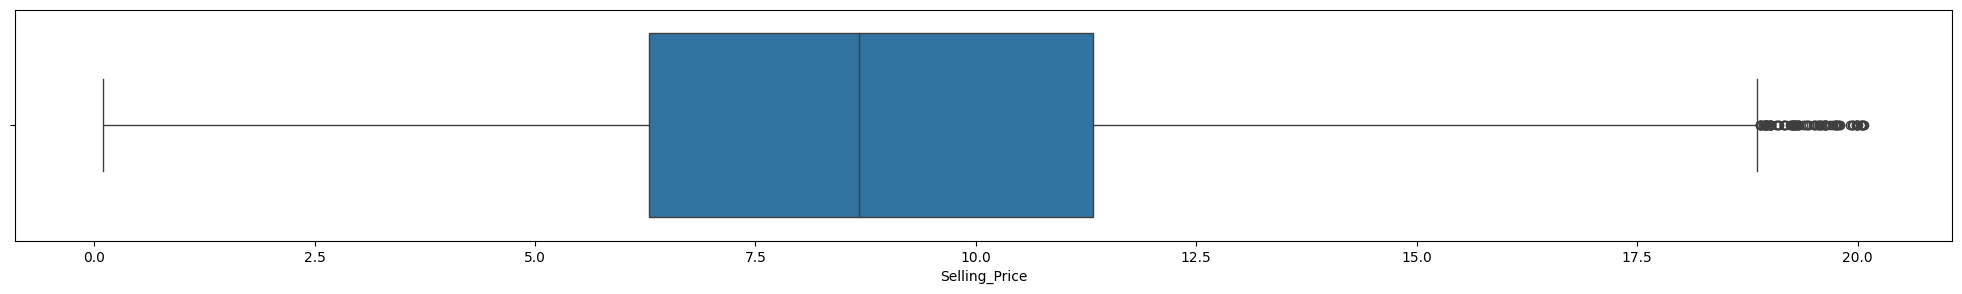

In [25]:
# réafficher les boxplots
for col in quantd.columns:
  boxplot_func(col)

In [26]:
# imputation des valeurs extrêmes
for col in quantd.columns:
  impute_func(df,col)

In [27]:
# Fractionner les données
x = df.iloc[:,:-1].values
y = df.iloc[:, -1].values

In [28]:
# importer RobustScaler
from sklearn.preprocessing import RobustScaler
# Normaliser x
scaler = RobustScaler()
scaler.fit(x)
x = scaler.transform(x)

In [29]:
# sauvegarde du scaler
jb.dump(scaler, '/content/model/scaler.joblib')

['/content/model/scaler.joblib']

In [30]:
from sklearn.model_selection import train_test_split
# Splitter les données en train, val et test
x_train, x_vt,y_train,y_vt = train_test_split(x,y , test_size = 0.2, random_state = 42)
# Splitter les données en val et test
x_val, x_test, y_val, y_test = train_test_split(x_vt, y_vt, test_size = 0.5, random_state = 42)

### <font color = 'bisque'>Multiple Linear Regression

In [31]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LinearRegression

# Validation croisée et figé
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# dictionnaire params
params_lr = {
    'fit_intercept': [True, False], #b=0
    'positive': [True, False] #true = valeur +, false = valeur + et -
 }
# Initialisation du modèle
lr = LinearRegression()
# Initialisation du GridSearchCV
grid_lr = GridSearchCV(lr, params_lr, cv = cv)
# Lancer la recherche
grid_lr.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LinearRegression(),
             param_grid={'fit_intercept': [True, False],
                         'positive': [True, False]})

In [32]:
# Récupérer le modèle optimal en partant de gridsearch
lr_model = grid_lr.best_estimator_

#### <font color = 'teal'> Evaluation du Linear Regression<font>

In [33]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error,root_mean_squared_error
# Calculer le R2 score et Mean Squarred Error
# from math import *
def evaluation(model):
  y_pred = model.predict(x_val)
  r2 = r2_score(y_val, y_pred)
  mse = mean_squared_error(y_val, y_pred)
  mae = mean_absolute_error(y_val, y_pred)
  rmse = root_mean_squared_error(y_val, y_pred)
  return r2, mse, mae, rmse

In [34]:
r2_lr, mse_lr, mae_lr, rmse_lr = evaluation(lr_model)
print(f"R2 : {r2_lr} --MSE : {mse_lr}  --RMSE : {rmse_lr} --MAE : {mae_lr}")

R2 : 0.6672156239359769 --MSE : 4.343157425325902  --RMSE : 2.0840243341491727 --MAE : 1.5764478603897638


### <font color = 'bisque'>Ridge Regression

In [35]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.linear_model import Ridge
# dictionnaire params
params_rr = {
    'fit_intercept': [True, False],
    'positive': [True, False],
    'alpha':np.logspace(-8,8, 100) #
 }
# Initialisation du modèle
rr = Ridge()
# Initialisation du GridSearchCV
grid_rr = GridSearchCV(rr, params_rr, cv = cv)
# Lancer la recherche
grid_rr.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Ridge(),
             param_grid={'alpha': array([1.00000000e-08, 1.45082878e-08, 2.10490414e-08, 3.05385551e-08,
       4.43062146e-08, 6.42807312e-08, 9.32603347e-08, 1.35304777e-07,
       1.96304065e-07, 2.84803587e-07, 4.13201240e-07, 5.99484250e-07,
       8.69749003e-07, 1.26185688e-06, 1.83073828e-06, 2.65608778e-06,
       3....
       8.49753436e+04, 1.23284674e+05, 1.78864953e+05, 2.59502421e+05,
       3.76493581e+05, 5.46227722e+05, 7.92482898e+05, 1.14975700e+06,
       1.66810054e+06, 2.42012826e+06, 3.51119173e+06, 5.09413801e+06,
       7.39072203e+06, 1.07226722e+07, 1.55567614e+07, 2.25701972e+07,
       3.27454916e+07, 4.75081016e+07, 6.89261210e+07, 1.00000000e+08]),
                         'fit_intercept': [True, False],
                         'positive': [True, False]})

In [36]:
# Récupérer le modèle optimal en partant de gridsearch
rr_model = grid_rr.best_estimator_


#### <font color = 'teal'> Evaluation du Ridge<font>

In [37]:
# Evaluation le modèle
r2_rr, mse_rr, mae_rr, rmse_rr = evaluation(rr_model)
print(f"R2 : {r2_rr} --MSE : {mse_rr}  --RMSE : {rmse_rr} --MAE : {mae_rr}")

R2 : 0.6671695942365673 --MSE : 4.343758157346861  --RMSE : 2.0841684570463257 --MAE : 1.5775494277027637


### <font color = 'bisque'>Decision Tree Regressor<font>

In [38]:
# Recherche des paramètres optimaux du decision tree
from sklearn.tree import DecisionTreeRegressor
# Dictionaire des params
params_dt = {
    'max_depth':np.arange(1,30),
    'criterion':['squared_error', 'absolute_error']
}
# Initialisation du modèle
dt = DecisionTreeRegressor(random_state = 42)
# Initialisation du GridSearchCV
grid_dt = GridSearchCV(dt, params_dt, cv = cv)
# Lancer la recherche
grid_dt.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeRegressor(random_state=42),
             param_grid={'criterion': ['squared_error', 'absolute_error'],
                         'max_depth': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29])})

In [39]:
# Récupérer le modèle optimal en partant de gridsearch
dt_model = grid_dt.best_estimator_

#### <font color = 'teal'> Evaluation du Decision Tree Regressor<font>

In [40]:
# Evaluation le modèle
r2_dt, mse_dt, mae_dt, rmse_dt = evaluation(dt_model)
print(f"R2 : {r2_dt} --MSE : {mse_dt}  --RMSE : {rmse_dt} --MAE : {mae_dt}")

R2 : 0.8363656702983748 --MSE : 2.1355859986200603  --RMSE : 1.461364430462183 --MAE : 1.0693836877903615


### <font color = 'bisque'>Random Forest Regressor<font>

In [41]:
from sklearn.ensemble import RandomForestRegressor

# Dictionnaires des paramètres
params_rf = {
    'n_estimators':np.arange(10,100,10),
    'max_depth':np.arange(1,15)
}
# Initialisation du modèle
rf =  RandomForestRegressor()
# Objet grid
grid_rf = GridSearchCV(rf, params_rf, cv=cv)
# Lancer la recherche
grid_rf.fit(x_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestRegressor(),
             param_grid={'max_depth': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14]),
                         'n_estimators': array([10, 20, 30, 40, 50, 60, 70, 80, 90])})

In [42]:
# Récupérer le modèle optimal en partant de gridsearch
rf_model = grid_rf.best_estimator_

#### <font color = 'teal'> Evaluation du Random Forest<font>

In [43]:
# Evaluation le modèle
r2_rf, mse_rf, mae_rf, rmse_rf = evaluation(rf_model)
print(f"R2 : {r2_rf} --MSE : {mse_rf}  --RMSE : {rmse_rf} --MAE : {mae_rf}")

R2 : 0.8623924701873042 --MSE : 1.7959111300699568  --RMSE : 1.3401160882811447 --MAE : 0.9861620487343028


In [44]:
# comparaison des métriques
list_names = ['LR', 'RR', 'DT', 'RF']
list_r2 = [r2_lr, r2_rr, r2_dt, r2_rf]
list_mse = [mse_lr, mse_rr, mse_dt, mse_rf]
list_mae = [mae_lr, mae_rr, mae_dt, mae_rf]
list_rmse = [rmse_lr, rmse_rr, rmse_dt, rmse_rf]
list_final = [list_r2, list_mse, list_mae, list_rmse]
for i in range(4):
  fig = px.bar(y = list_names, x = list_final[i], color= list_names, text_auto = True)
  fig.show()

In [45]:
# télécharger le modèle le plus performant
jb.dump(rf_model, '/content/model/rf_model.joblib')

['/content/model/rf_model.joblib']

### <font color = 'bisque'>Tester le modèle le plus performant<font>

In [46]:
#  echantillon des données test
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# Prédictions
y_pred_10 = rf_model.predict(x_test_10)
# Parcourir les prédictions
for i in range(10):
  print(f"Prédiction {i + 1} : {y_pred_10[i]:.2f}$ --Réel :{y_test_10[i]:.2f}$")

Prédiction 1 : 12.39$ --Réel :12.51$
Prédiction 2 : 5.57$ --Réel :7.25$
Prédiction 3 : 12.12$ --Réel :8.38$
Prédiction 4 : 6.69$ --Réel :5.59$
Prédiction 5 : 7.30$ --Réel :7.61$
Prédiction 6 : 8.55$ --Réel :8.39$
Prédiction 7 : 5.53$ --Réel :4.93$
Prédiction 8 : 5.31$ --Réel :4.79$
Prédiction 9 : 4.56$ --Réel :4.65$
Prédiction 10 : 9.22$ --Réel :8.96$
